In [1]:
import os
from pathlib import Path

root = Path.cwd()
while not (root / "src").exists():
    root = root.parent
os.chdir(root)

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from src.classification.dataset import eval_transform
from src.classification.predict import load_classifier
from src.common.config import load_yaml
from src.common.paths import CROPS_DIR, WEIGHTS_DIR
from src.explainability.gradcam import GradCAM, overlay

cfg = load_yaml("classifier")
gcfg = load_yaml("gradcam")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
run_name = f"{cfg['name']}_{cfg['arch']}_{cfg['version']}"
model, ckpt = load_classifier(WEIGHTS_DIR / f"{run_name}.pt", device)
classes = ckpt["classes"]
gradcam = GradCAM(model, model.get_submodule(gcfg["target_layer"]))
size = cfg["img_size"]
transform = eval_transform(size)

In [3]:
def show(name: str) -> str:
    return name.replace("_", " ")


def explain(stem: str):
    matches = list((CROPS_DIR / gcfg["split"]).rglob(f"{stem}.*"))
    if not matches:
        raise FileNotFoundError(f"Recorte não encontrado em {CROPS_DIR / gcfg['split']}: {stem}")
    path = matches[0]
    target = classes.index(path.parent.name)

    pil = Image.open(path).convert("RGB")
    tensor = transform(pil).unsqueeze(0).to(device)
    image = np.asarray(pil.resize((size, size))) / 255.0

    cam, probs = gradcam(tensor)
    pred = int(probs.argmax())
    panels = [
        (image, "original"),
        (overlay(image, cam, gcfg["alpha"], gcfg["colormap"]), "Grad-CAM: previsto"),
    ]
    if pred != target:
        cam_true, _ = gradcam(tensor, target)
        panels.append((overlay(image, cam_true, gcfg["alpha"], gcfg["colormap"]), "Grad-CAM: real"))

    title = f"real: {show(classes[target])} | previsto: {show(classes[pred])} ({probs[pred]:.0%})"
    return panels, title


def show_species(species: str, ok: str, erro: str) -> None:
    fig, axes = plt.subplots(2, 3, figsize=(10, 7.6))
    for row, name in zip(axes, (ok, erro)):
        panels, title = explain(name.split("_", 1)[1])
        for ax in row:
            ax.axis("off")
        for ax, (image, subtitle) in zip(row, panels):
            ax.imshow(image)
            ax.set_title(subtitle, fontsize=9)
        kind = "ACERTO" if name.startswith("ok_") else "ERRO"
        row[0].text(0, 1.14, f"{kind}  {title}", transform=row[0].transAxes, fontsize=9, fontweight="bold")
    fig.suptitle(species, fontsize=12, fontweight="bold")
    fig.subplots_adjust(top=0.9, hspace=0.45)
    plt.show()

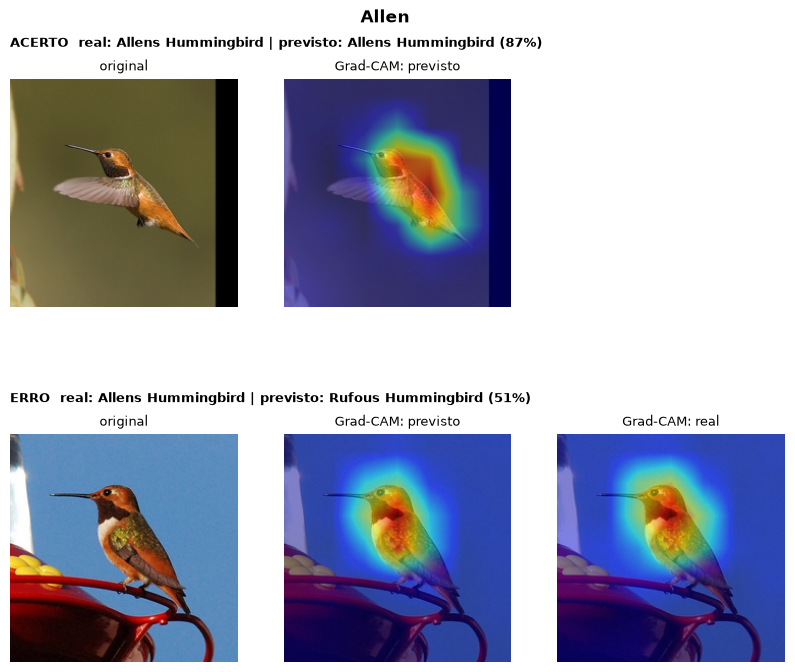

In [4]:
show_species("Allen",
             "ok_nabirds_3e9df62b2c9f43d786ae71265629151d",
             "erro_nabirds_000ef8cc723046a08415e13eb13bbc28")

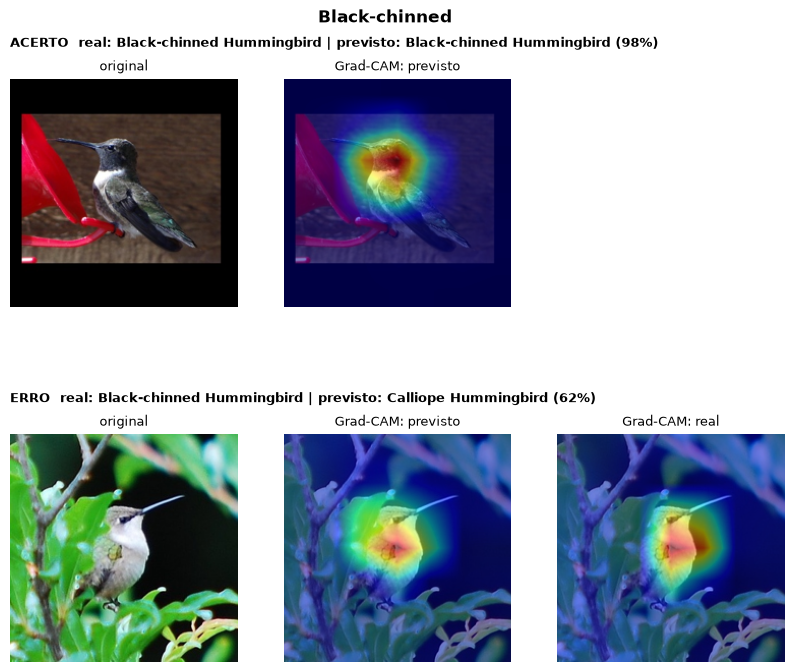

In [5]:
show_species("Black-chinned",
             "ok_nabirds_2f5321b1a50549a19068ef50e66d15d0",
             "erro_nabirds_6a78e05fcf324e7a8a57920ee8730deb")

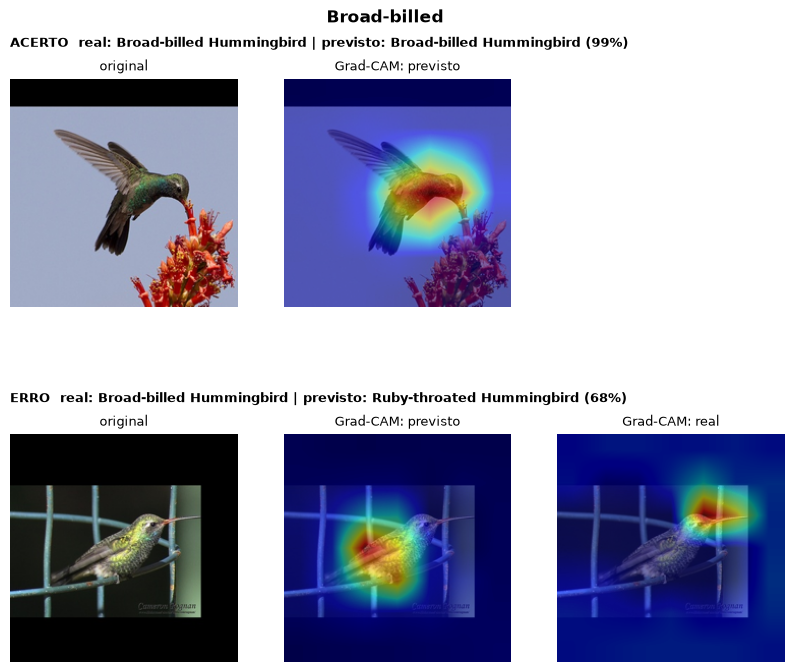

In [6]:
show_species("Broad-billed",
             "ok_nabirds_4e87b91adf2d442f9547d4a5c43e060e",
             "erro_nabirds_e446827c1b13457dbbffe5820e8fb69a")

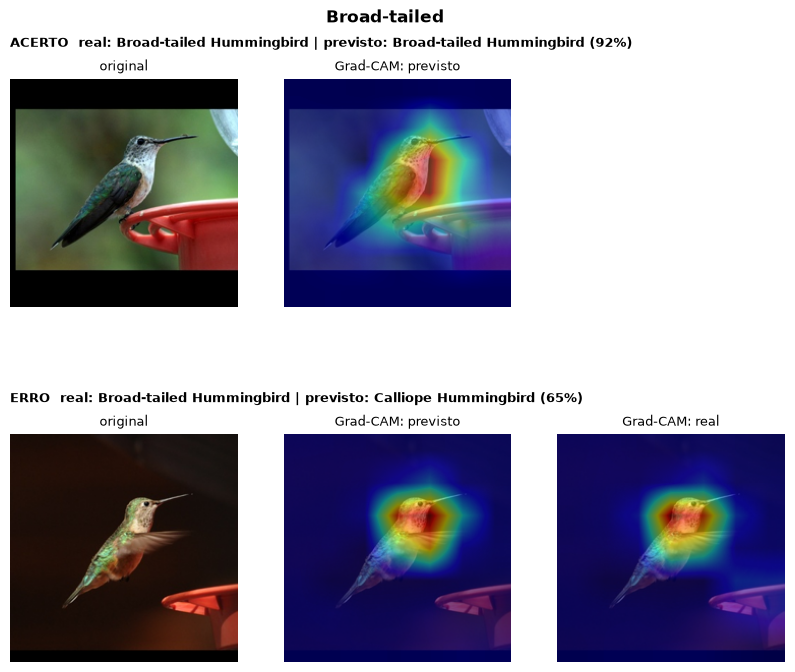

In [7]:
show_species("Broad-tailed",
             "ok_nabirds_2bb4ad76076a45bba36b88363c67dd64",
             "erro_nabirds_560e69d109c44295a18b7e5d5cf353bd")

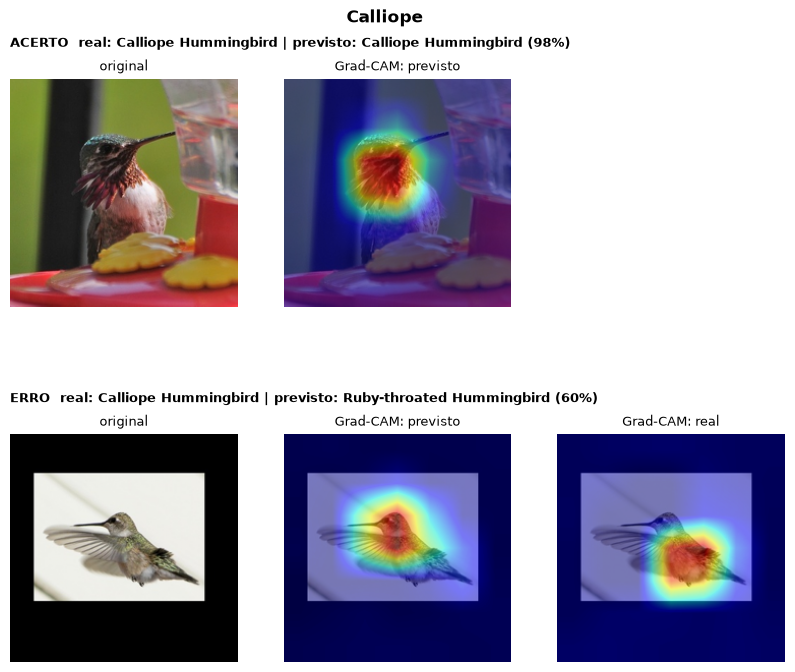

In [8]:
show_species("Calliope",
             "ok_nabirds_0b079c993e4a4bbbbfa9dc2e5f07a93b",
             "erro_nabirds_9c996eddd86b41fab3890aa132377e79")

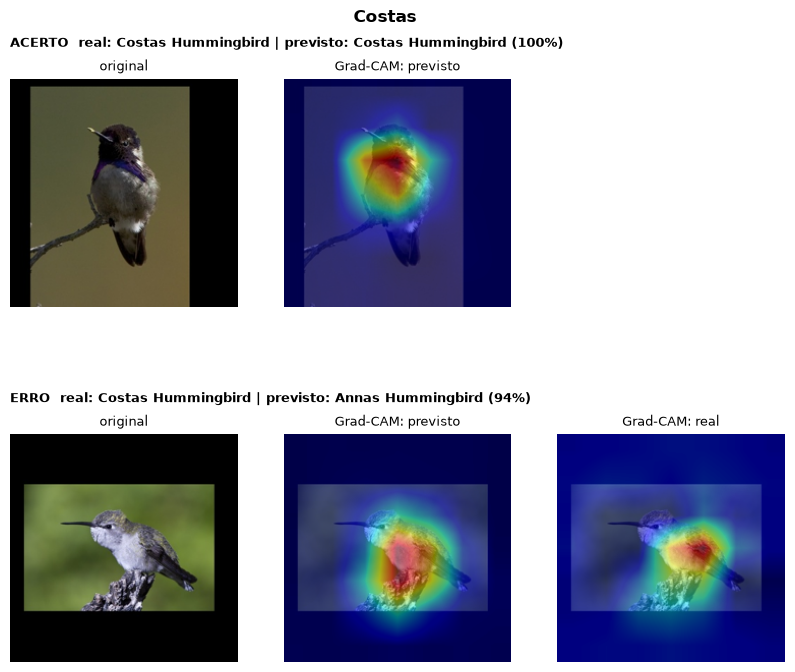

In [9]:
show_species("Costas",
             "ok_nabirds_3a36733ebae84dd5b8e1a1e1dca4df54",
             "erro_nabirds_a229251a30a141b29b7b19ba81c03efd")

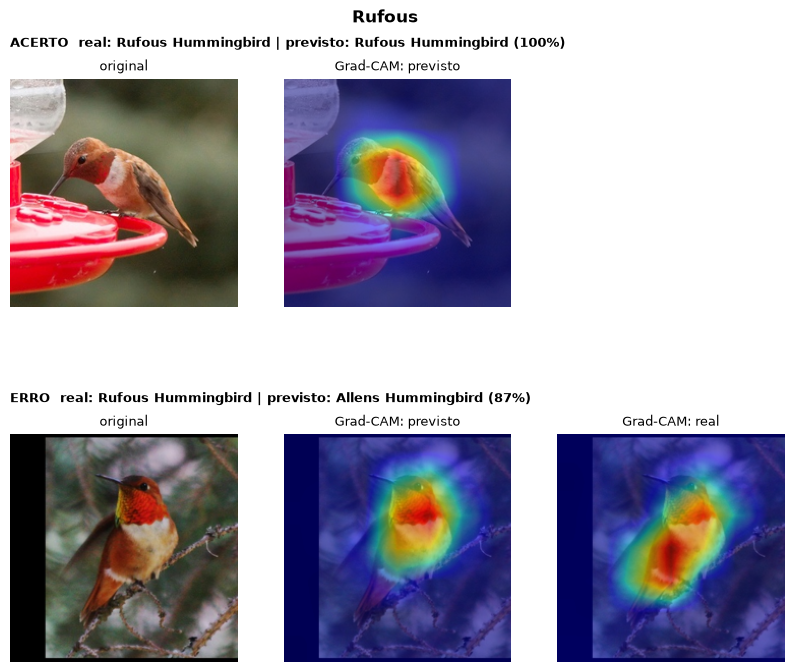

In [10]:
show_species("Rufous",
             "ok_cub200_Rufous_Hummingbird_0007_58433",
             "erro_nabirds_164fb44b2f324049a1061634451da4b2")

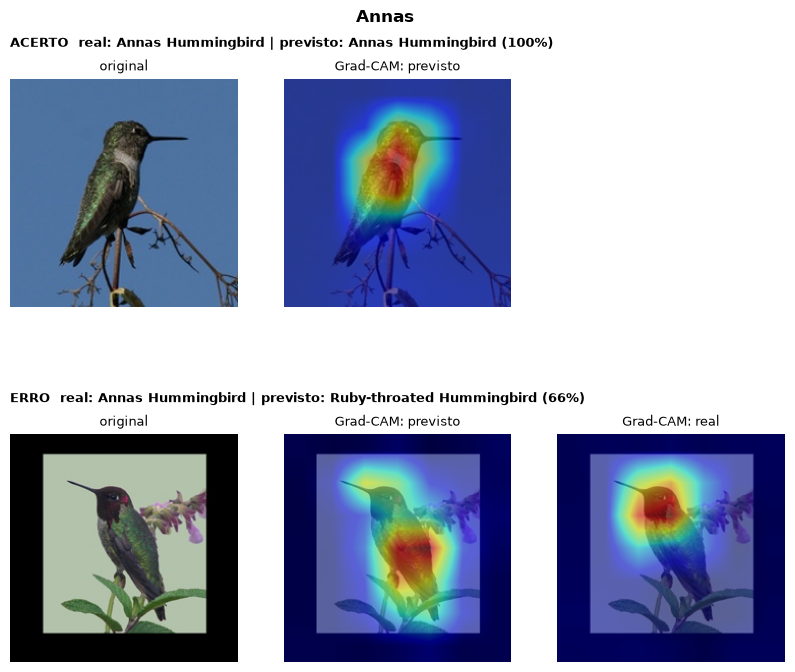

In [11]:
show_species("Annas",
             "ok_cub200_Anna_Hummingbird_0086_56495",
             "erro_cub200_Anna_Hummingbird_0042_55990")

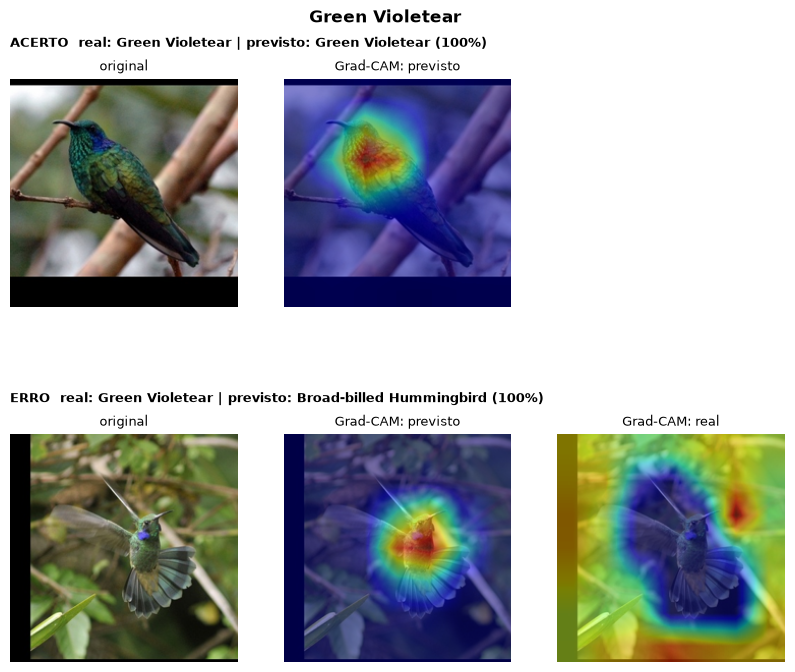

In [12]:
show_species("Green Violetear",
             "ok_cub200_Green_Violetear_0055_795712",
             "erro_cub200_Green_Violetear_0059_60873")

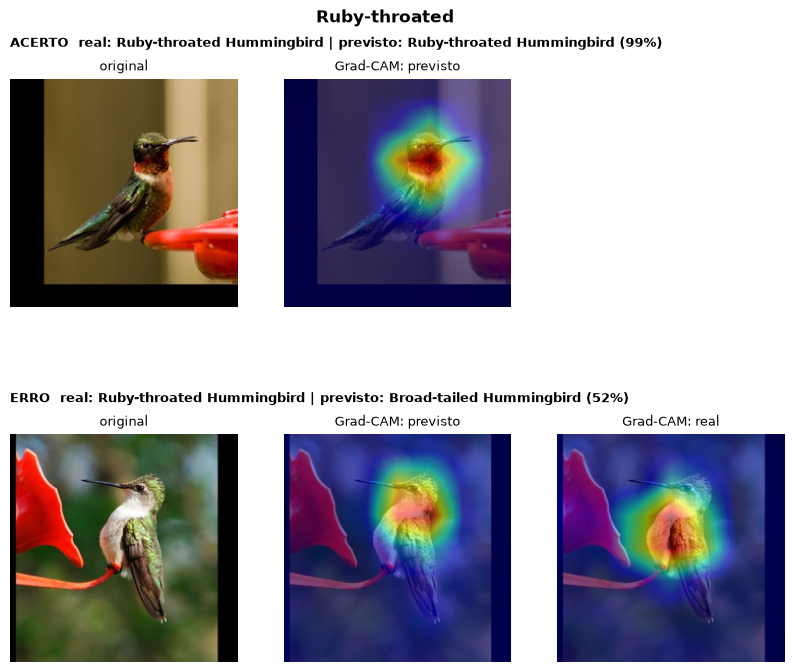

In [13]:
show_species("Ruby-throated",
             "ok_cub200_Ruby_Throated_Hummingbird_0064_57387",
             "erro_cub200_Ruby_Throated_Hummingbird_0007_57388")